# Hands-on Kamera: Filtering, Edge Detection, dan Hapus Background

Versi ini mengambil gambar **langsung dari kamera**, tanpa upload foto.

**Cara kerjanya berbeda di dua lingkungan:**

| Lingkungan | Cara ambil gambar | Catatan |
|---|---|---|
| **Google Colab** | JavaScript di browser (`getUserMedia`) | `cv2.VideoCapture(0)` **tidak bisa** dipakai di Colab, karena kodenya jalan di server Google, bukan di laptopmu. Klik **Izinkan** saat browser meminta akses kamera. |
| **Jupyter / VS Code lokal** | `cv2.VideoCapture(0)` | Mode live (bagian 5) hanya jalan di lokal. |

Bagian 1-4 bekerja di keduanya. Alurnya: ambil foto, filtering, edge detection, lalu hapus background.

Library: `numpy`, `opencv-python`, `matplotlib`, dan `numba` (opsional, untuk mempercepat loop konvolusi manual).

In [ ]:
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt

try:
    from numba import njit
    HAS_NUMBA = True
except ImportError:
    HAS_NUMBA = False

    def njit(*args, **kwargs):  # pengganti kosong: fungsi jalan sebagai Python biasa
        if len(args) == 1 and callable(args[0]):
            return args[0]
        return lambda f: f

IN_COLAB = 'google.colab' in sys.modules
MAX_SIDE = 320  # foto diperkecil ke sisi terpanjang ini supaya loop manual dan GrabCut tidak lama
print('Colab:', IN_COLAB, '| numba:', HAS_NUMBA)


def resize_max(a, max_side=MAX_SIDE):
    h, w = a.shape[:2]
    scale = max_side / max(h, w)
    if scale >= 1:
        return a
    return cv2.resize(a, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)


def normalize_to_uint8(a):
    a = a.astype(np.float64)
    a = a - a.min()
    if a.max() > 0:
        a = a / a.max() * 255
    return a.astype(np.uint8)


def show(images, titles, cols=3, size=(4, 4)):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size[0] * cols, size[1] * rows))
    axes = np.array(axes).reshape(-1)
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(im)
        ax.set_title(t)
        ax.axis('off')
    for ax in axes[len(images):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Colab: True | numba: True


## 1. Ambil foto dari kamera

`take_photo()` memilih cara yang sesuai dengan lingkungan. Di Colab akan muncul pratinjau kamera dengan tombol **Ambil foto**. Hasilnya berupa array BGR (format bawaan OpenCV).

In [ ]:
# ---------- Colab: ambil foto lewat JavaScript di browser ----------
def take_photo_colab(quality=0.9):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode

    js = Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Ambil foto';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """)
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    return cv2.imdecode(np.frombuffer(binary, np.uint8), cv2.IMREAD_COLOR)  # BGR


# ---------- Lokal: ambil satu frame lewat OpenCV ----------
def take_photo_local(cam_index=0, warmup=15):
    cap = cv2.VideoCapture(cam_index)
    if not cap.isOpened():
        raise RuntimeError('Kamera tidak bisa dibuka. Cek izin kamera, nilai cam_index (coba 1), '
                           'dan pastikan kamera tidak dipakai aplikasi lain.')
    try:
        for _ in range(warmup):  # buang beberapa frame awal supaya exposure menyesuaikan
            cap.read()
        ok, frame = cap.read()
    finally:
        cap.release()
    if not ok:
        raise RuntimeError('Gagal membaca frame dari kamera.')
    return frame


def take_photo():
    return take_photo_colab() if IN_COLAB else take_photo_local()

<IPython.core.display.Javascript object>

Ukuran asli: 640 x 480 | dipakai: 320 x 240


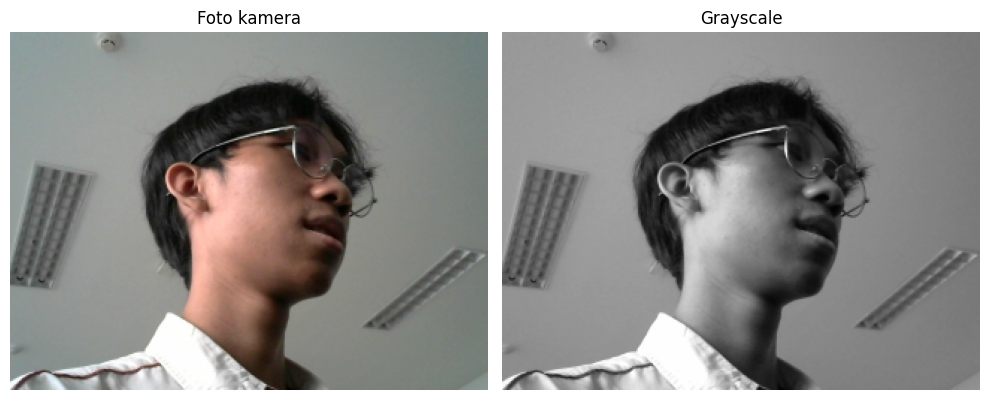

In [ ]:
raw_bgr = take_photo()
photo_bgr = resize_max(raw_bgr)                          # BGR, untuk fungsi OpenCV
photo = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2RGB)       # RGB, untuk matplotlib
gray = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2GRAY)

print('Ukuran asli:', raw_bgr.shape[1], 'x', raw_bgr.shape[0], '| dipakai:', photo.shape[1], 'x', photo.shape[0])
cv2.imwrite('foto_kamera.jpg', raw_bgr)                  # simpan foto asli (di Colab: panel Files di kiri)
show([photo, gray], ['Foto kamera', 'Grayscale'], cols=2, size=(5, 5))

## 2. Filtering pada foto kamera

Dimulai dari konvolusi manual dengan loop. Hasilnya dibandingkan dengan OpenCV untuk memastikan benar, lalu dipakai untuk mean, Gaussian, dan median.

Selisih maksimum manual vs OpenCV: 0.0


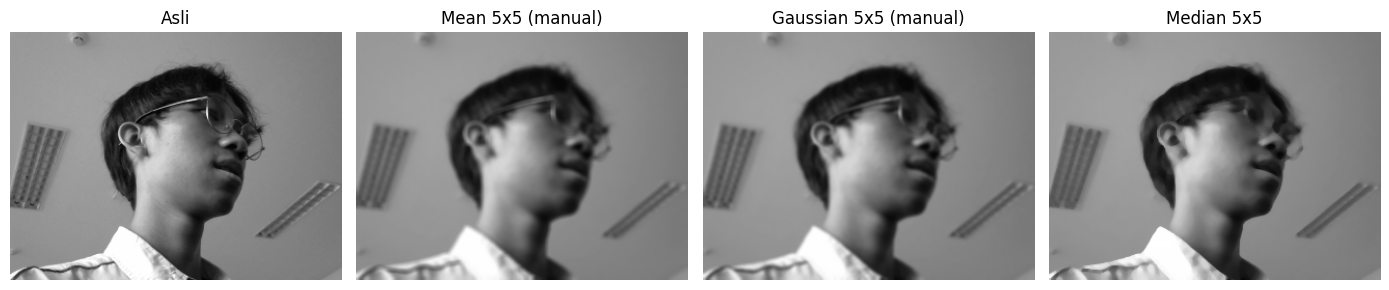

In [ ]:
@njit
def _convolve_loops(padded, flipped, h, w):
    kh, kw = flipped.shape
    out = np.zeros((h, w), dtype=np.float64)
    for y in range(h):
        for x in range(w):
            s = 0.0
            for i in range(kh):
                for j in range(kw):
                    s += padded[y + i, x + j] * flipped[i, j]
            out[y, x] = s
    return out


def convolve2d(image, kernel, padding='reflect'):
    image = image.astype(np.float64)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    mode = {'zero': 'constant', 'replicate': 'edge', 'reflect': 'reflect'}[padding]
    padded = np.pad(image, ((ph, ph), (pw, pw)), mode=mode)
    flipped = np.ascontiguousarray(np.flipud(np.fliplr(kernel)), dtype=np.float64)
    h, w = image.shape
    return _convolve_loops(padded, flipped, h, w)


def to_uint8(a):
    return np.clip(a, 0, 255).astype(np.uint8)


def gaussian_kernel(size=5, sigma=1.0):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return k / k.sum()


# Verifikasi manual vs OpenCV
k_mean = np.ones((5, 5)) / 25.0
convolve2d(gray[:8, :8], k_mean)  # pemanasan (kompilasi numba)
manual = convolve2d(gray, k_mean)
ref = cv2.filter2D(gray.astype(np.float64), -1, k_mean, borderType=cv2.BORDER_REFLECT_101)
print('Selisih maksimum manual vs OpenCV:', np.abs(manual - ref).max())

mean_out = to_uint8(manual)
gauss_out = to_uint8(convolve2d(gray, gaussian_kernel(5, 1.5)))
median_out = cv2.medianBlur(gray, 5)

show([gray, mean_out, gauss_out, median_out],
     ['Asli', 'Mean 5x5 (manual)', 'Gaussian 5x5 (manual)', 'Median 5x5'], cols=4, size=(3.5, 3.5))

Foto kamera biasanya punya sedikit noise, terutama di ruangan redup. Supaya efek filternya jelas, tambahkan noise buatan lalu bandingkan:

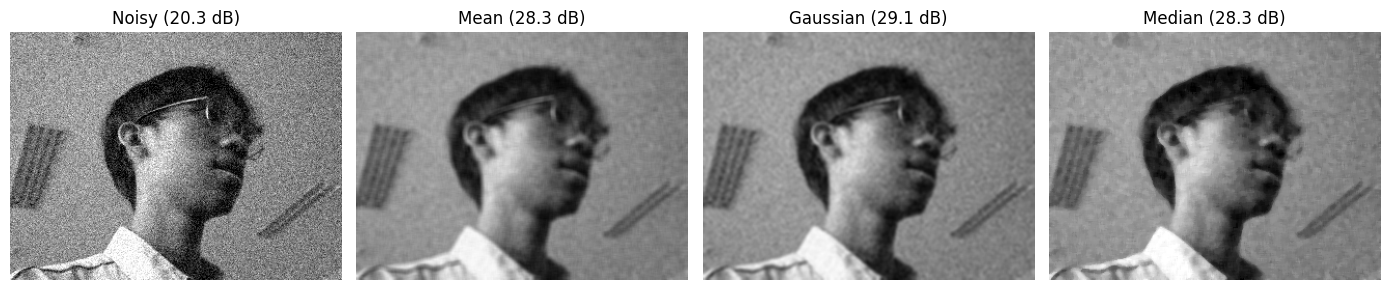

In [ ]:
rng = np.random.default_rng(0)
NOISE_SIGMA = 25   # ubah untuk noise lebih kuat/lemah
noisy = to_uint8(gray + rng.normal(0, NOISE_SIGMA, gray.shape))

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)

n_mean = to_uint8(convolve2d(noisy, np.ones((5, 5)) / 25.0))
n_gauss = to_uint8(convolve2d(noisy, gaussian_kernel(5, 1.5)))
n_median = cv2.medianBlur(noisy, 5)

show([noisy, n_mean, n_gauss, n_median],
     [f'Noisy ({psnr(gray, noisy):.1f} dB)', f'Mean ({psnr(gray, n_mean):.1f} dB)',
      f'Gaussian ({psnr(gray, n_gauss):.1f} dB)', f'Median ({psnr(gray, n_median):.1f} dB)'],
     cols=4, size=(3.5, 3.5))

## 3. Edge detection pada foto kamera

Sobel (turunan orde pertama), LoG (orde kedua), dan Canny. Ubah tiga nilai di baris pertama untuk bereksperimen dengan threshold.

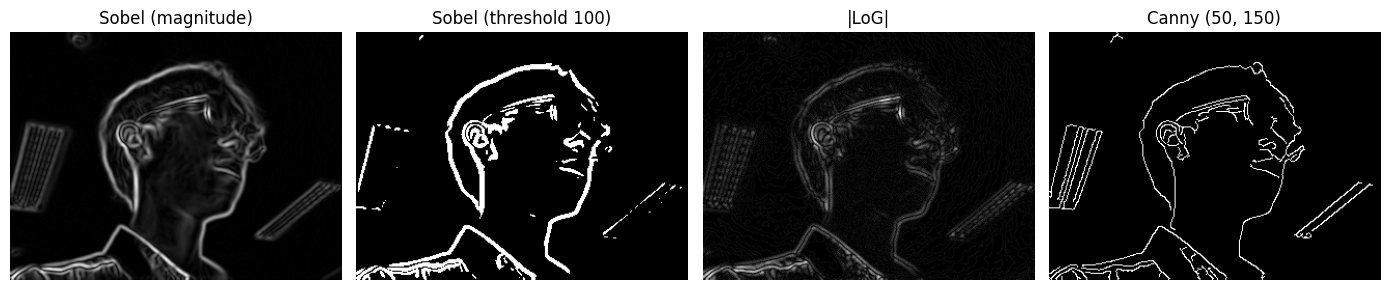

In [ ]:
SOBEL_T = 100                       # threshold magnitude Sobel
CANNY_LOW, CANNY_HIGH = 50, 150     # dua threshold Canny

blur = cv2.GaussianBlur(gray, (5, 5), 1.4)          # blur dulu supaya noise tidak jadi tepi

gx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)
mag = np.hypot(gx, gy)
sobel_bin = ((mag > SOBEL_T) * 255).astype(np.uint8)

log = cv2.Laplacian(cv2.GaussianBlur(gray, (7, 7), 1.4), cv2.CV_64F)
canny = cv2.Canny(blur, CANNY_LOW, CANNY_HIGH)

show([normalize_to_uint8(mag), sobel_bin, normalize_to_uint8(np.abs(log)), canny],
     ['Sobel (magnitude)', f'Sobel (threshold {SOBEL_T})', '|LoG|', f'Canny ({CANNY_LOW}, {CANNY_HIGH})'],
     cols=4, size=(3.5, 3.5))

## 4. Hapus background (GrabCut)

Berdiri **di tengah frame** dengan background yang tidak terlalu mirip warna bajumu. Kotak awal (`RECT_FRAC`) ditentukan sebagai **persentase** dari ukuran foto: `(x, y, lebar, tinggi)`. Atur supaya kotak hijau di pratinjau melingkupi seluruh dirimu dengan sedikit ruang kosong di sekelilingnya.

Setelah GrabCut, mask dirapikan dengan morfologi (open dan close), diambil komponen terbesar, lubang diisi, lalu dihaluskan dengan median filter.

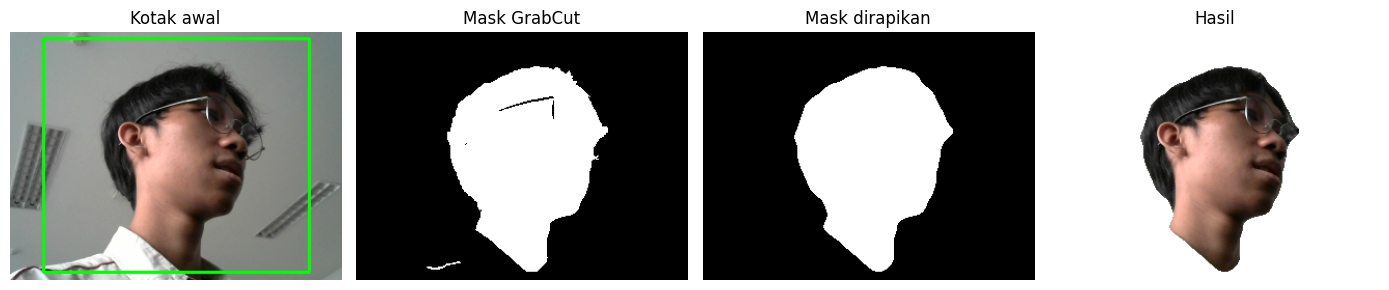

In [ ]:
RECT_FRAC = (0.10, 0.03, 0.80, 0.94)   # (x, y, lebar, tinggi) sebagai pecahan ukuran foto
GC_ITER = 8

H, W = photo.shape[:2]
rect = (int(RECT_FRAC[0] * W), int(RECT_FRAC[1] * H), int(RECT_FRAC[2] * W), int(RECT_FRAC[3] * H))

gc_mask = np.zeros((H, W), np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)
cv2.grabCut(photo_bgr, gc_mask, rect, bgd_model, fgd_model, GC_ITER, cv2.GC_INIT_WITH_RECT)
mask_gc = np.where((gc_mask == 1) | (gc_mask == 3), 255, 0).astype(np.uint8)


def largest_component(mask):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return mask
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return ((lab == k) * 255).astype(np.uint8)


k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
m = cv2.morphologyEx(mask_gc, cv2.MORPH_OPEN, k)     # buang duri dan bintik kecil
m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)          # tutup celah kecil
m = largest_component(m)                             # sisakan objek terbesar
inv = m.copy()                                       # isi lubang di dalam objek
cv2.floodFill(inv, np.zeros((H + 2, W + 2), np.uint8), (0, 0), 255)
m = m | cv2.bitwise_not(inv)
mask_clean = cv2.medianBlur(m, 7)                    # haluskan tepi

preview = photo.copy()
x, y, rw, rh = rect
cv2.rectangle(preview, (x, y), (x + rw, y + rh), (0, 255, 0), 2)
result = np.where(mask_clean[..., None] > 0, photo, 255).astype(np.uint8)

show([preview, mask_gc, mask_clean, result],
     ['Kotak awal', 'Mask GrabCut', 'Mask dirapikan', 'Hasil'], cols=4, size=(3.5, 3.5))

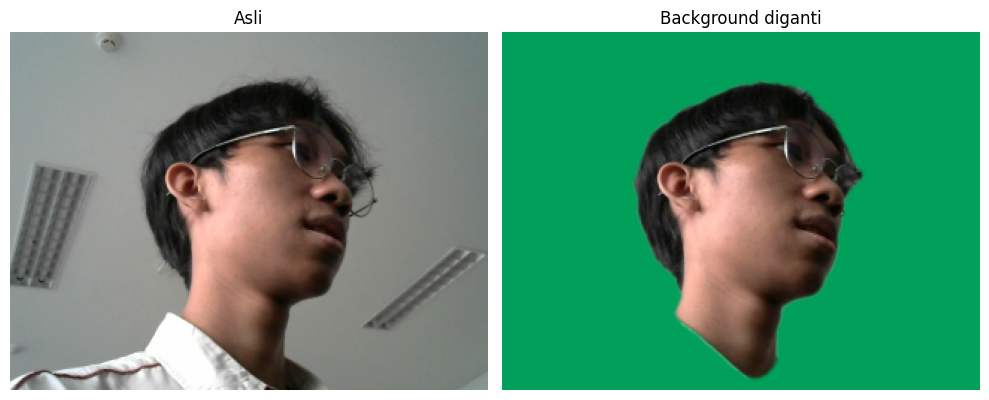

Tersimpan: kamera_tanpa_background.png


In [ ]:
# PNG transparan: mask jadi alpha channel (tepi dihaluskan sedikit)
soft = cv2.GaussianBlur(mask_clean, (5, 5), 0)
rgba = np.dstack([photo_bgr, soft])                  # BGR + alpha
cv2.imwrite('kamera_tanpa_background.png', rgba)

# Ganti background dengan warna lain
alpha = (soft / 255.0)[..., None]
green = np.full_like(photo, (0, 160, 90))
composite = (alpha * photo + (1 - alpha) * green).astype(np.uint8)
show([photo, composite], ['Asli', 'Background diganti'], cols=2, size=(5, 5))
print('Tersimpan: kamera_tanpa_background.png')

# Di Colab, unduh hasilnya:
# from google.colab import files; files.download('kamera_tanpa_background.png')

## 5. Mode live (hanya Jupyter / VS Code lokal)

Memproses video dari kamera secara real-time. `cv2.imshow` **tidak bisa** dipakai di Colab, jadi sel ini otomatis dilewati di sana.

Tombol di jendela video: **1** asli, **2** grayscale, **3** Gaussian, **4** median, **5** Sobel, **6** Canny, **q** keluar. Klik jendela videonya dulu supaya tombol terbaca.

In [ ]:
def run_live(cam_index=0):
    cap = cv2.VideoCapture(cam_index)
    if not cap.isOpened():
        print('Kamera tidak bisa dibuka. Cek izin kamera atau coba cam_index=1.')
        return
    names = {'1': 'Asli', '2': 'Grayscale', '3': 'Gaussian', '4': 'Median', '5': 'Sobel', '6': 'Canny'}
    mode = '1'
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame = resize_max(frame, 480)
            g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            if mode == '1':
                out = frame
            elif mode == '2':
                out = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
            elif mode == '3':
                out = cv2.GaussianBlur(frame, (9, 9), 2)
            elif mode == '4':
                out = cv2.medianBlur(frame, 5)
            elif mode == '5':
                b = cv2.GaussianBlur(g, (5, 5), 1.4)
                sx = cv2.Sobel(b, cv2.CV_64F, 1, 0, ksize=3)
                sy = cv2.Sobel(b, cv2.CV_64F, 0, 1, ksize=3)
                out = cv2.cvtColor(cv2.convertScaleAbs(np.hypot(sx, sy)), cv2.COLOR_GRAY2BGR)
            else:
                b = cv2.GaussianBlur(g, (5, 5), 1.4)
                out = cv2.cvtColor(cv2.Canny(b, 50, 150), cv2.COLOR_GRAY2BGR)
            out = out.copy()
            cv2.putText(out, names[mode], (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
            cv2.imshow('Live (1-6 ganti mode, q keluar)', out)
            key = cv2.waitKey(1) & 0xFF
            if key == ord('q'):
                break
            if chr(key) in names:
                mode = chr(key)
    finally:
        cap.release()
        cv2.destroyAllWindows()


if IN_COLAB:
    print('Mode live tidak tersedia di Colab. Jalankan notebook ini di Jupyter/VS Code lokal untuk mencobanya.')
else:
    run_live()

Mode live tidak tersedia di Colab. Jalankan notebook ini di Jupyter/VS Code lokal untuk mencobanya.
